# Gaussian Mixture Models (GMM) and Expectation-Maximization (EM)

## 1. Definition and intuition
A Gaussian Mixture Model represents a density as a weighted sum of Gaussian components. Each point has a *soft* membership probability for every component rather than a single hard cluster assignment. GMMs can model ellipsoidal clusters with different sizes and orientations.

## 2. Probability model
For $x\in\mathbb{R}^d$,
$$
p(x)=\sum_{k=1}^{K}\pi_k\,\mathcal{N}(x\mid\mu_k,\Sigma_k),\quad
\pi_k\ge0,\quad \sum_k\pi_k=1.
$$
The latent variable $z_i$ identifies which Gaussian generated sample $x_i$. Parameters are component weights $\pi_k$, means $\mu_k$, and covariance matrices $\Sigma_k$.

## 3. EM algorithm
**E-step:** compute responsibilities
$$
r_{ik}=P(z_i=k\mid x_i)=
\frac{\pi_k\mathcal{N}(x_i\mid\mu_k,\Sigma_k)}
{\sum_j\pi_j\mathcal{N}(x_i\mid\mu_j,\Sigma_j)}.
$$
**M-step:** use responsibilities as fractional memberships:
$$
N_k=\sum_i r_{ik},\quad \pi_k=N_k/n,\quad
\mu_k=\frac{\sum_i r_{ik}x_i}{N_k},
$$
$$
\Sigma_k=\frac{\sum_i r_{ik}(x_i-\mu_k)(x_i-\mu_k)^T}{N_k}.
$$

## 4. Why EM works—and what it does not prove
EM alternates maximizing a lower bound on the log-likelihood: the E-step makes the bound tight for the current parameters, and the M-step maximizes that bound. Under regularity conditions, observed-data log-likelihood does not decrease each iteration. This does **not** guarantee a global maximum; initialization matters, and Gaussian-mixture likelihoods can have singular solutions without covariance regularization.

## 5. Assumptions and failure modes
A GMM assumes a mixture of Gaussian densities is useful for the data. Clusters need not be spherical, but overlapping components can be hard to identify. Feature scaling, outliers, covariance singularity, too many components, and local optima matter. A fitted mixture is a density model; components are not always meaningful real-world groups.

## 6. Dataset

Use synthetic blobs with unequal spread, then compare posterior probabilities against hard labels. The true synthetic labels are only for evaluation; EM does not use them during fitting.

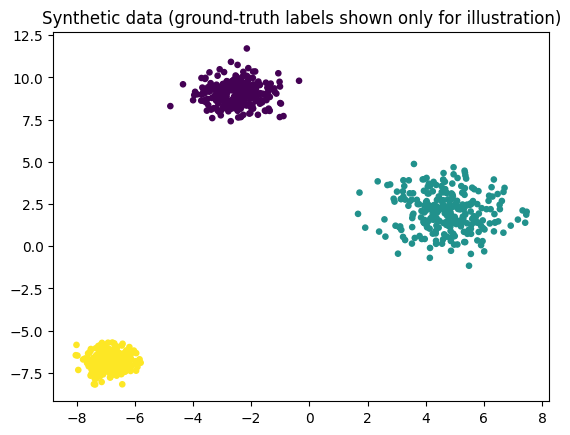

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

SEED = 42
X, y_true = make_blobs(n_samples=800, centers=3, n_features=2,
                       cluster_std=[0.7, 1.1, 0.45], random_state=SEED)
X = X.astype(float)
plt.scatter(X[:, 0], X[:, 1], c=y_true, s=14)
plt.title("Synthetic data (ground-truth labels shown only for illustration)")
plt.show()


## 7. From-scratch GMM with full covariance

For numerical stability, the log Gaussian density uses the covariance log-determinant and a linear solve rather than explicitly inverting every covariance matrix. A small diagonal `reg_covar * I` prevents singular covariance estimates. This is a compact educational EM implementation.

In [2]:
def log_gaussian_pdf(X, mean, cov):
    X = np.asarray(X, dtype=float)
    d = X.shape[1]
    cov = cov + 1e-6 * np.eye(d)
    sign, logdet = np.linalg.slogdet(cov)
    if sign <= 0:
        raise ValueError("Covariance must be positive definite after regularization")
    diff = X - mean
    solved = np.linalg.solve(cov, diff.T).T
    quad = np.einsum("ij,ij->i", diff, solved)
    return -0.5 * (d*np.log(2*np.pi) + logdet + quad)

def fit_gmm_em(X, n_components, max_iter=100, tol=1e-4, reg_covar=1e-5, random_state=42):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or len(X) == 0 or not np.isfinite(X).all():
        raise ValueError("X must be a non-empty finite 2D array")
    n, d = X.shape
    if not 1 <= n_components <= n or max_iter < 1 or tol < 0 or reg_covar <= 0:
        raise ValueError("Invalid GMM parameters")
    rng = np.random.default_rng(random_state)
    means = X[rng.choice(n, n_components, replace=False)].copy()
    global_cov = np.cov(X, rowvar=False) + reg_covar*np.eye(d)
    covs = np.repeat(global_cov[None, :, :], n_components, axis=0)
    weights = np.full(n_components, 1/n_components)
    history = []
    for _ in range(max_iter):
        log_joint = np.column_stack([
            np.log(max(weights[k], 1e-15)) + log_gaussian_pdf(X, means[k], covs[k])
            for k in range(n_components)
        ])
        log_norm = logsumexp(log_joint, axis=1)
        resp = np.exp(log_joint - log_norm[:, None])
        history.append(float(log_norm.sum()))
        nk = resp.sum(axis=0) + 1e-12
        weights = nk / n
        means = (resp.T @ X) / nk[:, None]
        new_covs = []
        for k in range(n_components):
            diff = X - means[k]
            cov = (diff.T * resp[:, k]) @ diff / nk[k]
            cov += reg_covar * np.eye(d)
            new_covs.append(cov)
        covs = np.asarray(new_covs)
        if len(history) > 1 and abs(history[-1] - history[-2]) < tol:
            break
    log_joint = np.column_stack([
        np.log(max(weights[k], 1e-15)) + log_gaussian_pdf(X, means[k], covs[k])
        for k in range(n_components)
    ])
    log_norm = logsumexp(log_joint, axis=1)
    resp = np.exp(log_joint - log_norm[:, None])
    return {"weights": weights, "means": means, "covariances": covs,
            "responsibilities": resp, "log_likelihood_history": history}

def gmm_predict_proba(X, model):
    X = np.asarray(X, dtype=float)
    log_joint = np.column_stack([
        np.log(max(model["weights"][k], 1e-15)) +
        log_gaussian_pdf(X, model["means"][k], model["covariances"][k])
        for k in range(len(model["weights"]))
    ])
    return np.exp(log_joint - logsumexp(log_joint, axis=1, keepdims=True))

scratch = fit_gmm_em(X, 3, random_state=SEED)
labels_scratch = scratch["responsibilities"].argmax(axis=1)
print("Scratch ARI:", round(adjusted_rand_score(y_true, labels_scratch), 4))
print("Weights:", np.round(scratch["weights"], 3))
print("EM iterations:", len(scratch["log_likelihood_history"]))
print("Final log likelihood:", round(scratch["log_likelihood_history"][-1], 2))
assert np.allclose(scratch["responsibilities"].sum(axis=1), 1.0, atol=1e-7)


Scratch ARI: 1.0
Weights: [0.334 0.334 0.333]
EM iterations: 13
Final log likelihood: -2568.31


## 8. Compare with scikit-learn

Cluster component labels are arbitrary, so compare with label-permutation-invariant ARI and confirm posterior rows sum to one.

In [3]:
sk_gmm = GaussianMixture(n_components=3, covariance_type="full", n_init=5,
                         reg_covar=1e-5, random_state=SEED).fit(X)
sk_labels = sk_gmm.predict(X)
sk_proba = sk_gmm.predict_proba(X)
print("scikit-learn ARI:", round(adjusted_rand_score(y_true, sk_labels), 4))
print("scikit-learn converged:", sk_gmm.converged_, "iterations:", sk_gmm.n_iter_)
print("Max row-sum error:", np.abs(sk_proba.sum(axis=1)-1).max())
assert np.allclose(sk_proba.sum(axis=1), 1.0, atol=1e-7)


scikit-learn ARI: 1.0
scikit-learn converged: True iterations: 2
Max row-sum error: 4.440892098500626e-16


## 9. Hyperparameters, complexity, and scaling

- `n_components`: mixture complexity; compare BIC/AIC and domain plausibility.
- `covariance_type`: `full`, `tied`, `diag`, or `spherical` changes flexibility and parameter count.
- `reg_covar`: protects against singular covariance matrices.
- `n_init`, `max_iter`, `tol`: affect local-optimum risk and runtime.
- With full covariance, a rough per-iteration cost is $O(nKd^2 + Kd^3)$ for density/linear algebra, plus storage $O(nd+Kd^2)$. Prediction responsibilities have similar per-sample cost.
- Millions of rows: use mini-batch/online EM variants, reduce dimension, or use diagonal/tied covariances; chunk the E-step to bound intermediate memory.
- GPU: the dense matrix operations are parallelizable, but a reliable, efficient EM implementation needs careful batched covariance/linear algebra and device-memory management.

## 10. Best practices and synthesis
Use multiple initializations, inspect convergence and covariance conditioning, standardize when scales differ, and compare with density/cluster alternatives. EM monotonically improves the likelihood under its update assumptions, but the final answer is a local optimum—not a proof that the chosen component count is correct.

In [4]:
assert np.isfinite(scratch["means"]).all()
assert np.isfinite(scratch["covariances"]).all()
assert np.all(scratch["weights"] >= 0) and np.isclose(scratch["weights"].sum(), 1)
try:
    fit_gmm_em(np.array([1, 2, 3]), 2)
except ValueError:
    pass
else:
    raise AssertionError("Expected invalid dimensionality to raise")
print("All GMM/EM checks passed.")


All GMM/EM checks passed.
